# Problem ID: CAT02_PROB02 — Battery-Aware Cleaning

## Real-World Narrative
A smart cleaning robot operates in a 5×5 facility. **Objective:** Balance cleaning with low-battery recharging.

**State Space S:** position, local dirt percept, dirt severity, battery level, obstacle percepts, dock distance, and problem-specific percept memory.

**Action Space A:** UP, DOWN, LEFT, RIGHT, CLEAN, RECHARGE (valid actions depend on the percept).

**Reward / Transition Mechanics:** cleaning dirt earns positive reward proportional to severity; movement has a small cost; invalid actions are penalized; battery decreases during movement/cleaning; docking enables recharge; new dirt may appear dynamically.

## Deliverables
1. Implement `choose_action(self, percept)` in Cell 4.
2. Implement `update_agent(...)` in Cell 5.
3. Do not modify locked cells.


In [1]:
# Cell 2: Standard Imports and Parameters (LOCKED)
import numpy as np
import matplotlib.pyplot as plt
import random
np.random.seed(42); random.seed(42)
GRID_SIZE=5; MAX_STEPS=60; EPISODES=40
ALPHA=0.2; GAMMA=0.9; EPSILON=0.1


In [2]:
# Cell 3: EnvironmentEngine (LOCKED)
class EnvironmentEngine:
    def __init__(self, size=GRID_SIZE):
        self.size=size; self.dock=(0,0); self.obstacles={(1,1),(3,3)}
    def reset(self):
        self.pos=(0,0); self.battery=100; self.dirt={(2,2):2,(4,4):1,(1,4):1}; self.steps=0
        return self._percept(new_dirt=False)
    def _percept(self,new_dirt=False):
        moves={"UP":(-1,0),"DOWN":(1,0),"LEFT":(0,-1),"RIGHT":(0,1)}
        valid=[]; blocked=[]; neighbours={}
        for a,(dr,dc) in moves.items():
            nr,nc=self.pos[0]+dr,self.pos[1]+dc
            if 0<=nr<self.size and 0<=nc<self.size and (nr,nc) not in self.obstacles:
                valid.append(a); neighbours[a]=(nr,nc)
            else: blocked.append(a)
        return {"position":self.pos,"battery":self.battery,"dirt":self.pos in self.dirt,"dirt_level":self.dirt.get(self.pos,0),"valid_moves":valid,"blocked":blocked,"neighbours":neighbours,"dock_distance":abs(self.pos[0])+abs(self.pos[1]),"new_dirt":new_dirt}
    def step(self,action):
        reward=-0.2; new_dirt=False
        if action=="CLEAN":
            if self.pos in self.dirt: reward=5*self.dirt.pop(self.pos); self.battery-=2
            else: reward=-1
        elif action=="RECHARGE":
            if self.pos==self.dock: self.battery=min(100,self.battery+25); reward=1
            else: reward=-2
        elif action in self._percept()["valid_moves"]:
            self.pos=self._percept()["neighbours"][action]; self.battery-=1
        else: reward=-2
        self.steps+=1
        if self.steps%7==0 and (4,0) not in self.dirt: self.dirt[(4,0)]=1; new_dirt=True
        done=self.battery<=0 or self.steps>=MAX_STEPS or not self.dirt
        return self._percept(new_dirt),reward,done


In [3]:
class SmartCleaningAgent:
    def __init__(self, alpha=ALPHA, gamma=GAMMA, epsilon=EPSILON):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.q = {}
        self.dirty_memory = set()
        self.blocked_memory = set()
        self.battery_history = []
        self.priority_score = 0.0
        self.min_battery = 100
        self.resume_target = None
        self.recharge_count = 0
        self.visited = set()
        self.coverage = 0
        self.cleaned_recently = set()
        self.percept_history = []
        self.action_value = {}
        self.energy_cost = {'UP': 1, 'DOWN': 1, 'LEFT': 1, 'RIGHT': 1,
                            'CLEAN': 2, 'RECHARGE': 0.1}

    def _move_toward(self, pos, target, valid):
        candidates = []
        deltas = {'UP': (-1, 0), 'DOWN': (1, 0),
                  'LEFT': (0, -1), 'RIGHT': (0, 1)}
        for action in valid:
            dr, dc = deltas[action]
            new_pos = (pos[0] + dr, pos[1] + dc)
            distance = abs(new_pos[0] - target[0]) + abs(new_pos[1] - target[1])
            candidates.append((distance, action))
        return min(candidates)[1] if candidates else 'RECHARGE'

    def _move_to_dock(self, percept):
        return self._move_toward(tuple(percept['position']), (0, 0), percept['valid_moves'])

    def choose_action(self, percept):
        self.battery_history.append(percept['battery'])
        if percept['battery'] <= 20:
            return 'RECHARGE'
        if percept['dirt']:
            return 'CLEAN'
        return random.choice(percept['valid_moves'])


In [4]:
def update_agent(self, percept, action, reward, next_percept, done):
    self.battery_history.append(percept['battery'])
    self.min_battery = min(self.min_battery, percept['battery'])
    self.q[action] = self.q.get(action, 0.0) + self.alpha * (reward - self.q.get(action, 0.0))

SmartCleaningAgent.update_agent = update_agent


In [5]:
# Cell 6: Test Driver (LOCKED)
env=EnvironmentEngine(); agent=SmartCleaningAgent()
rewards_history=[]; steps_history=[]
for ep in range(EPISODES):
    percept=env.reset(); total=0; steps=0; done=False
    while not done:
        action=agent.choose_action(percept)
        next_percept,reward,done=env.step(action)
        agent.update_agent(percept,action,reward,next_percept,done)
        percept=next_percept; total+=reward; steps+=1
    rewards_history.append(total); steps_history.append(steps)
print('Average reward:', round(float(np.mean(rewards_history)),2))


Average reward: 9.29


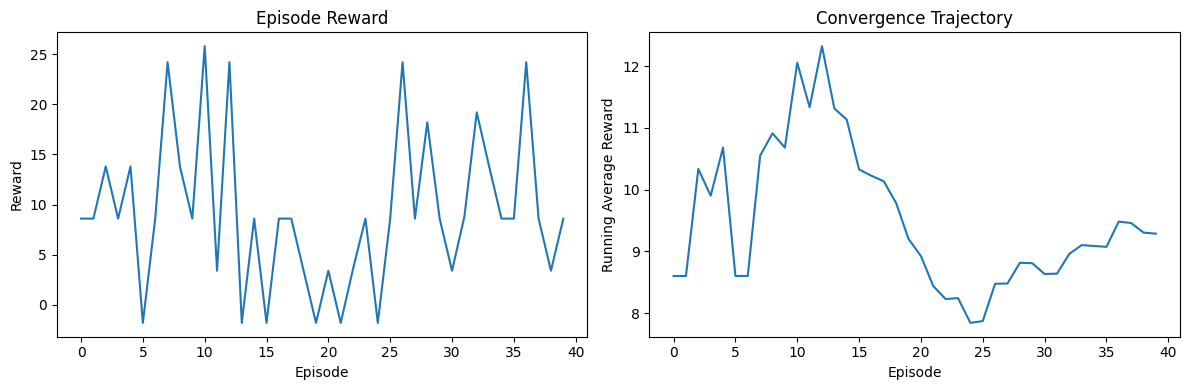

In [6]:
# Cell 7: Visualization (LOCKED)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1); plt.plot(rewards_history); plt.title('Episode Reward'); plt.xlabel('Episode'); plt.ylabel('Reward')
plt.subplot(1,2,2); plt.plot(np.cumsum(rewards_history)/(np.arange(len(rewards_history))+1)); plt.title('Convergence Trajectory'); plt.xlabel('Episode'); plt.ylabel('Running Average Reward')
plt.tight_layout(); plt.show()
